# Cell Tracking — TemporalUNet3D + SimpleNodeTransformer

Mirrors the structure of `nnUNet.ipynb` but for the tracking task.

Pipeline:
1. **Data** — zarr images + geff tracks
2. **Dataset** — `TrackDataset`: sliding windows of W consecutive frames
3. **Model** — `UNetNodeTransformer`: UNet features + detection head + cross-attention edge predictor
4. **Inference** — load checkpoint, detect peaks, show results

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
cd ../src

/data/kaggle-cell-tracking/src


In [3]:
import glob
import json
import torch
import zarr
import polars as pl
import numpy as np
import tracksdata as td
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from pathlib import Path
from collections import Counter

In [4]:
from tracking.dataset import TrackDataset
from tracking.data import load_dataset_windows

from tracking.targets import detect_and_match, build_matched_edge_targets, pos_embed_torch
from tracking.losses import TrackingLoss, detection_loss, edge_loss
from tracking.post_process import detect_peaks
from tracking.plot import plot_detection, plot_edges, plot_sample
from utils.plot import scatter_by_depth

from model_zoo.models_track import define_track_model, UNetNodeTransformer
from tracking_cellmot.io import open_dataset, list_datasets


In [5]:
from params import TRAIN_DIR, LOG_FOLDER, SCALE

TRAIN_DIR = Path(TRAIN_DIR)
LOG_FOLDER = Path(LOG_FOLDER)

DOWNSAMPLE = (1, 1, 1)   # (Z, Y, X) strides used at training time
WINDOW_SIZE = 2

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

Device: cuda


## 1. Data

Each sample is a pair of files:
- `.zarr` — 4D image volume `(T, Z, Y, X)` uint16
- `.geff` — cell tracks (node coordinates + edges between consecutive frames)

In [6]:
all_paths = list_datasets(TRAIN_DIR, require_geff=True)

embryos = [p.name.split('_')[0] for p in all_paths]
Counter(embryos)

Counter({'6bba': 128, '44b6': 71})

## 2. Dataset — what gets fed to the model

`TrackDataset` produces fixed-size windows of `W` consecutive frames:
- `imgs`: `(W, Z_ds, Y_ds, X_ds)` float16 — normalised, spatially downsampled
- `coords`: `(W, max_nodes, 3)` — GT node positions in downsampled space
- `masks`: `(W, max_nodes)` bool — which slots are real nodes
- `targets`: `(W-1, max_nodes, max_nodes)` — GT transition matrices

In [7]:
ds_path = np.random.choice(all_paths)
ds_path.name

'6bba_b204cac7'

In [8]:
vm, windows = load_dataset_windows(
    ds_path, window_size=WINDOW_SIZE,
)

print(vm)

VideoMeta(zarr_path=PosixPath('../input/train/6bba_b204cac7.zarr'), image_shape=(100, 64, 256, 256), voxel_size=(1.625, 0.40625, 0.40625), q_low=27.0, q_high=1188.0000001407898)


In [9]:
win_idx = max(range(len(windows)), key=lambda i: sum(windows[i].node_counts))  # max frames number
w = windows[win_idx]

In [10]:
ds = TrackDataset(
    [(vm, windows)],
    augment=False,
    crop_size=None,  # (64, 128, 128)
    weak_positives_cfg={
        "use": True,
        "max_nodes": 512,
        "ignore_max_nodes": 512,
        # Weak positives from image local maxima
        "threshold": 1.0,  # Multiplication factor for the image intensity peak threshold
        "nms_um": 5.0,
        "dir": None,
        # Which image-peak implementation to use.
        "strategy": "legacy",  # "v2"  # v2 requires a lower threshold !
        "ignore_threshold": 0.25,  # v2 only - multiplier for the ignore bar
        "ignore_nms_um": 5.0,   # v2 only - exclusion radius for the ignore pass
        "ignore_floor": 0.0,    # v2 only - absolute floor on the ignore bar; not fold-symmetric
        # Weak positives from pl_folder
        "pl_folder": None,  # "../logs/2026-08-19/14/preds_pl/",
        "pl_ignore_folder": None,  # Expects lower threshold coords
        "ignore_min_dist_um": 7.0,  # the pl_ignore_folder path only
    },
)

In [11]:
%%time
sample = ds[win_idx]

print("\nSample keys/shapes:")
for k, v in sample.items():
    if isinstance(v, torch.Tensor):
        print(f"  {k:12s}  {tuple(v.shape)}  {v.dtype}")


Sample keys/shapes:
  coords        (2, 9, 3)  torch.float32
  masks         (2, 9)  torch.bool
  targets       (1, 9, 9)  torch.float32
  node_counts   (2,)  torch.int64
  imgs          (2, 64, 256, 256)  torch.float16
  weak_positives  (2, 512, 3)  torch.float32
  ignore_positives  (2, 1, 3)  torch.float32
  image_shape   (4,)  torch.int64
  voxel_size    (3,)  torch.float32
CPU times: user 923 ms, sys: 736 ms, total: 1.66 s
Wall time: 70.9 ms


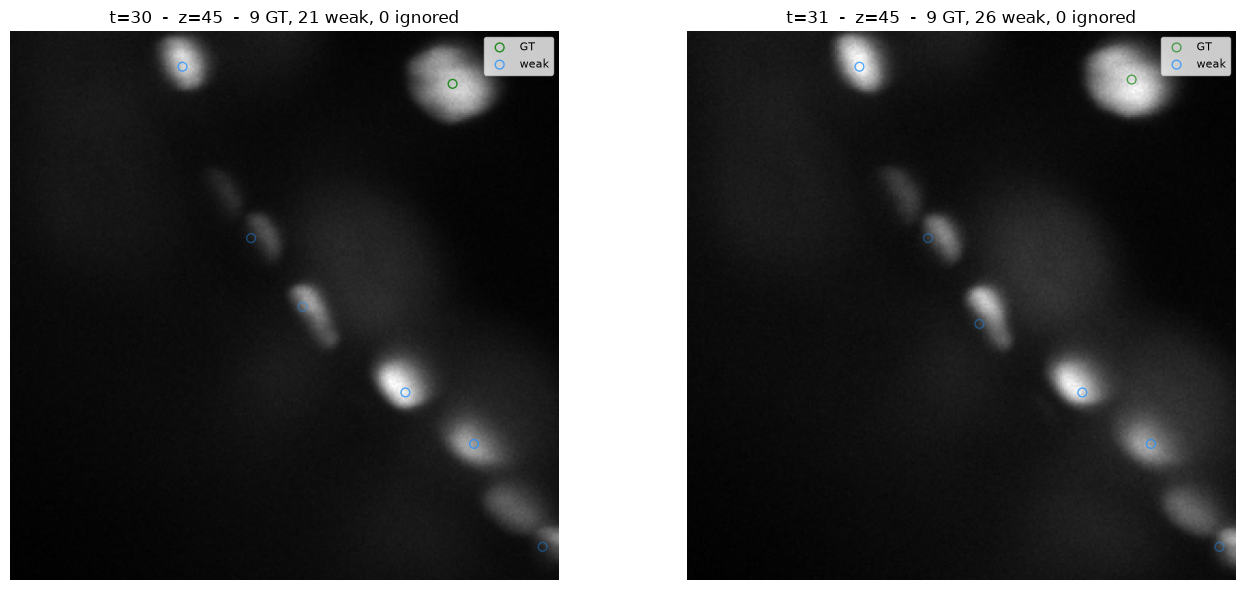

In [12]:
sample = ds[win_idx]

zs = np.unique(sample["coords"].numpy()[:, :, 0]).astype(int)
z = np.random.choice(zs)
# z = 55

plot_sample(sample, t_start=windows[win_idx].t_start, tol=3, z=z)

## 3. Model

`UNetNodeTransformer` = `TemporalUNet3D` + detection head + `SimpleNodeTransformer`

1. **encode(imgs)** → UNet features `(B, W, C, Z_ds, Y_ds, X_ds)` + detection logits `(B, 1, Z_ds, Y_ds, X_ds)` per frame
2. **detect_and_match** → detected peak coords + sinusoidal pos-embeddings
3. **_index_features** → UNet features at detected positions
4. **predict_edges** → cross-attention transformer → `(B, N_src, N_tgt)` edge logits

In [75]:
from model_zoo.models_track import define_track_model

In [76]:
model = define_track_model(
    unet_out_channels=32,
    unet_layers=[16, 16, 16],
    transformer_hidden=32,
    transformer_heads=4,
    transformer_blocks=4,
    unet_pool_stride=(1, 2, 2),
    unet_n_decode_steps=1,
    verbose=1
).to(device)

In [77]:
# weights = torch.load("/data/kaggle-cell-tracking/logs/2026-08-13/25/fold_0/ckpt_08000.pt")
# # weights = torch.load("/data/kaggle-cell-tracking/logs/2026-08-13/7/fold_0/ckpt_final.pt")
# model.load_state_dict(weights['model_state_dict'])


In [78]:
print(f"Total parameters : {model.count_parameters() / 1e6:.2f}M")
print(f"  UNet           : {sum(p.numel() for p in model.unet.parameters()) / 1e6:.2f}M")
print(f"  Detect head    : {sum(p.numel() for p in model.detect_head.parameters()) / 1e6:.2f}M")
print(f"  Transformer    : {sum(p.numel() for p in model.transformer.parameters()) / 1e6:.2f}M")

Total parameters : 0.10M
  UNet           : 0.06M
  Detect head    : 0.00M
  Transformer    : 0.04M


In [79]:
sample = ds[win_idx]
imgs_batch = sample["imgs"].float().unsqueeze(0).to(device)

bs, window_size, d, h, w = imgs_batch.shape
print('Input shape:', imgs_batch.shape)

coords = sample["coords"].to(device).unsqueeze(0)
masks = sample["masks"].to(device).unsqueeze(0)
targets = sample["targets"].to(device).unsqueeze(0)

image_shape = tuple(sample["image_shape"].tolist())
voxel_size = tuple(sample["voxel_size"].tolist())

image_shape, voxel_size

Input shape: torch.Size([1, 2, 64, 256, 256])


((100, 64, 256, 256), (1.625, 0.40625, 0.40625))

In [80]:
%%time
unet_out, det_logits = model.encode(imgs_batch)

UNetNodeTransformer - Encode - Input shape: torch.Size([1, 2, 64, 256, 256])
TemporalUNet3D - Encoder Block 0 - Input shape: torch.Size([2, 1, 64, 256, 256])
TemporalUNet3D - Encoder Block 1 - Input shape: torch.Size([2, 16, 64, 128, 128])
TemporalUNet3D - Encoder Block 2 - Input shape: torch.Size([2, 16, 64, 64, 64])
TemporalUNet3D - Encoder output shape: torch.Size([2, 16, 32, 32, 32])
TemporalUNet3D - Decoder Block 0 upsampled shape: torch.Size([2, 16, 64, 64, 64]) - skip shape: torch.Size([2, 16, 64, 64, 64])
UNetNodeTransformer - Encode - UNet output shape: torch.Size([1, 2, 32, 64, 64, 64])
UNetNodeTransformer - Encode - Detect logits shape: [torch.Size([1, 1, 64, 64, 64]), torch.Size([1, 1, 64, 64, 64])]
CPU times: user 7.77 ms, sys: 3.57 ms, total: 11.3 ms
Wall time: 10.9 ms


In [81]:
bs, window_size, d, h, w = imgs_batch.shape
d_out, h_out, w_out = unet_out.shape[-3:]

unet_scaling = (d // d_out, h // h_out, w // w_out)

print(unet_scaling)
print(voxel_size)

(1, 4, 4)
(1.625, 0.40625, 0.40625)


In [82]:
det_probas = imgs_batch[:, :, ::unet_scaling[0], ::unet_scaling[1], ::unet_scaling[2]]
det_probas.size()

torch.Size([1, 2, 64, 64, 64])

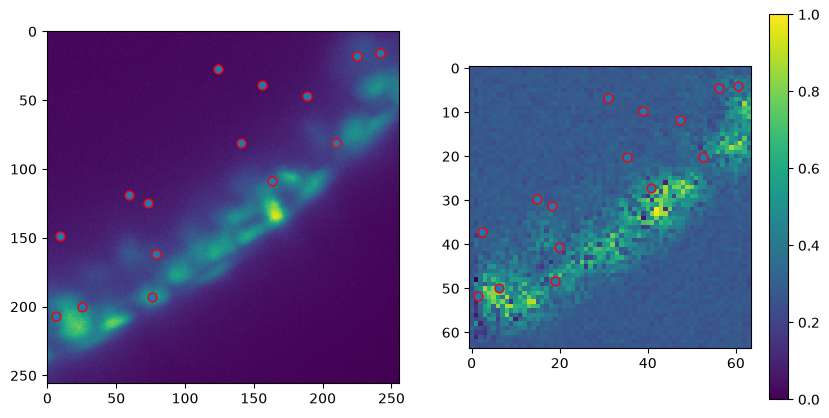

Pred peaks size: torch.Size([1, 8956, 3])


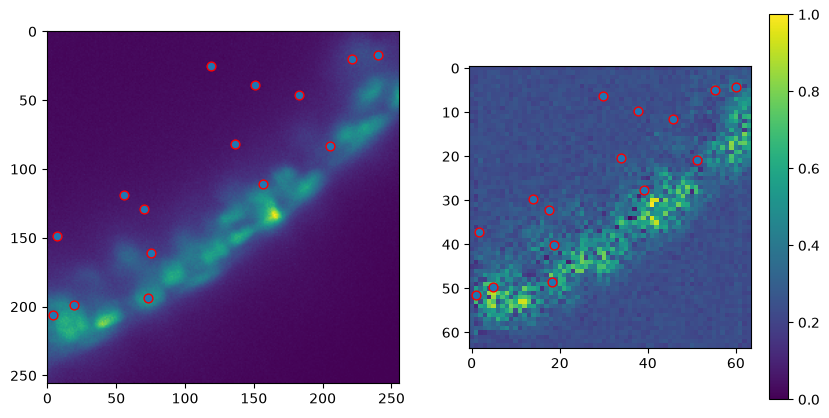

Pred peaks size: torch.Size([1, 8990, 3])


In [83]:
frame_det = []

frame = 63

with torch.no_grad():
    det_probas = [det.sigmoid() for det in det_logits]
    for i in range(WINDOW_SIZE):         

        plt.figure(figsize=(10, 5))
        plt.subplot(1, 2, 1)
        pts = coords[:, i].reshape(-1, 3).cpu().numpy()
        plt.imshow(sample["imgs"][i].squeeze()[frame].cpu().numpy())
        scatter_by_depth(plt, pts, frame, "r", tol=3, s=40)
        plt.subplot(1, 2, 2)
        plt.imshow(det_probas[i].squeeze()[frame].cpu().numpy())
        scatter_by_depth(
            plt, pts / np.asarray(unet_scaling), frame / unet_scaling[0],
            "r", tol=3, s=40,
        )
        plt.colorbar()
        plt.show()

        det_coords, det_pos_embed, det_mask, matches = detect_and_match(
            det_probas[i],
            coords[:, i],
            masks[:, i],
            image_shape,
            voxel_size=voxel_size,
            unet_scaling=unet_scaling,
            pool_kernel_um=5,
            frame_index=i,
            window_size=WINDOW_SIZE,
            det_threshold=0.5
        )
        unet_feat = model._index_features(
            unet_out[:, i], det_coords, det_mask,
        )
        frame_det.append((det_coords, det_pos_embed, det_mask, matches, unet_feat))

        print("Pred peaks size:", det_coords.size())
        # print("Pred mask:", det_mask)
        # if matches[0].max() > -1:
        #     print(f"Peak matches with gt {coords[:, i][int(matches[0].max())]}: {det_coords[0][int(matches[0].argmax())]}")
        # else:
        #     print("No matches")

        # break

In [84]:
# edge_logits_list = []
# edge_targets_list = []
# det_mask_pairs = []

# for i in range(WINDOW_SIZE - 1):
#     ns = frame_det[i][0].shape[1]  # number of source nodes
#     nt = frame_det[i + 1][0].shape[1]  # number of target nodes

#     pair_target = build_matched_edge_targets(
#         frame_det[i][3],  # matches at frame i
#         frame_det[i + 1][3],  # matches at frame i+1
#         targets[:, i],  # gt transition matrix at frame i
#         ns,  # number of source nodes
#         nt,  # number of target nodes
#     )  # which node pairs are linked

#     # Forward of the edge scorer - score each node pair
#     edge_log = model.predict_edges(
#         unet_feat_src=frame_det[i][4],  # frame i UNet features
#         unet_feat_tgt=frame_det[i + 1][4],  # frame i+1 UNet features
#         coords_src=frame_det[i][0],  # frame i coords
#         coords_tgt=frame_det[i + 1][0],  # frame i+1 coords
#         pos_feat_src=frame_det[i][1],  # frame i pos-embed
#         pos_feat_tgt=frame_det[i + 1][1],  # frame i+1 pos-embed
#         mask_src=frame_det[i][2],  # frame i mask
#         mask_tgt=frame_det[i + 1][2],  # frame i+1 mask
#     )
#     edge_logits_list.append(edge_log)
#     edge_targets_list.append(pair_target)
#     det_mask_pairs.append((frame_det[i][2], frame_det[i + 1][2]))

### Loss

In [85]:
from tracking.losses import TrackingLoss

In [86]:
criterion = TrackingLoss(**{
        "det_loss_weight": 1.0,
        "det_neg_weight": 0.1,
        "det_weak_weight": 0.3,        # weight for image-derived weak positives
        "det_weak_smoothing": 0.1,     # smoothing factor for weak positives
        "det_ignore_radius": 2.0,      # grid voxels around an uncertain peak with no negative term
    }
)

#### Detection target & weight

What `detection_loss` actually sees for frame `i`: the Gaussian-splatted target heatmap (GT peaks at 1.0, weak positives at `1 - weak_smoothing`) and the per-voxel positive weight (1 for GT, `det_weak_weight` for weak positives, 0 elsewhere — everything else is background, discounted by `det_neg_weight`).

z=0 (z_det=0)  |  15 GT, 81 weak, 2 ignore in this frame
n_pos = 17  |  ignored voxels = 9  |  heat max = 1.00


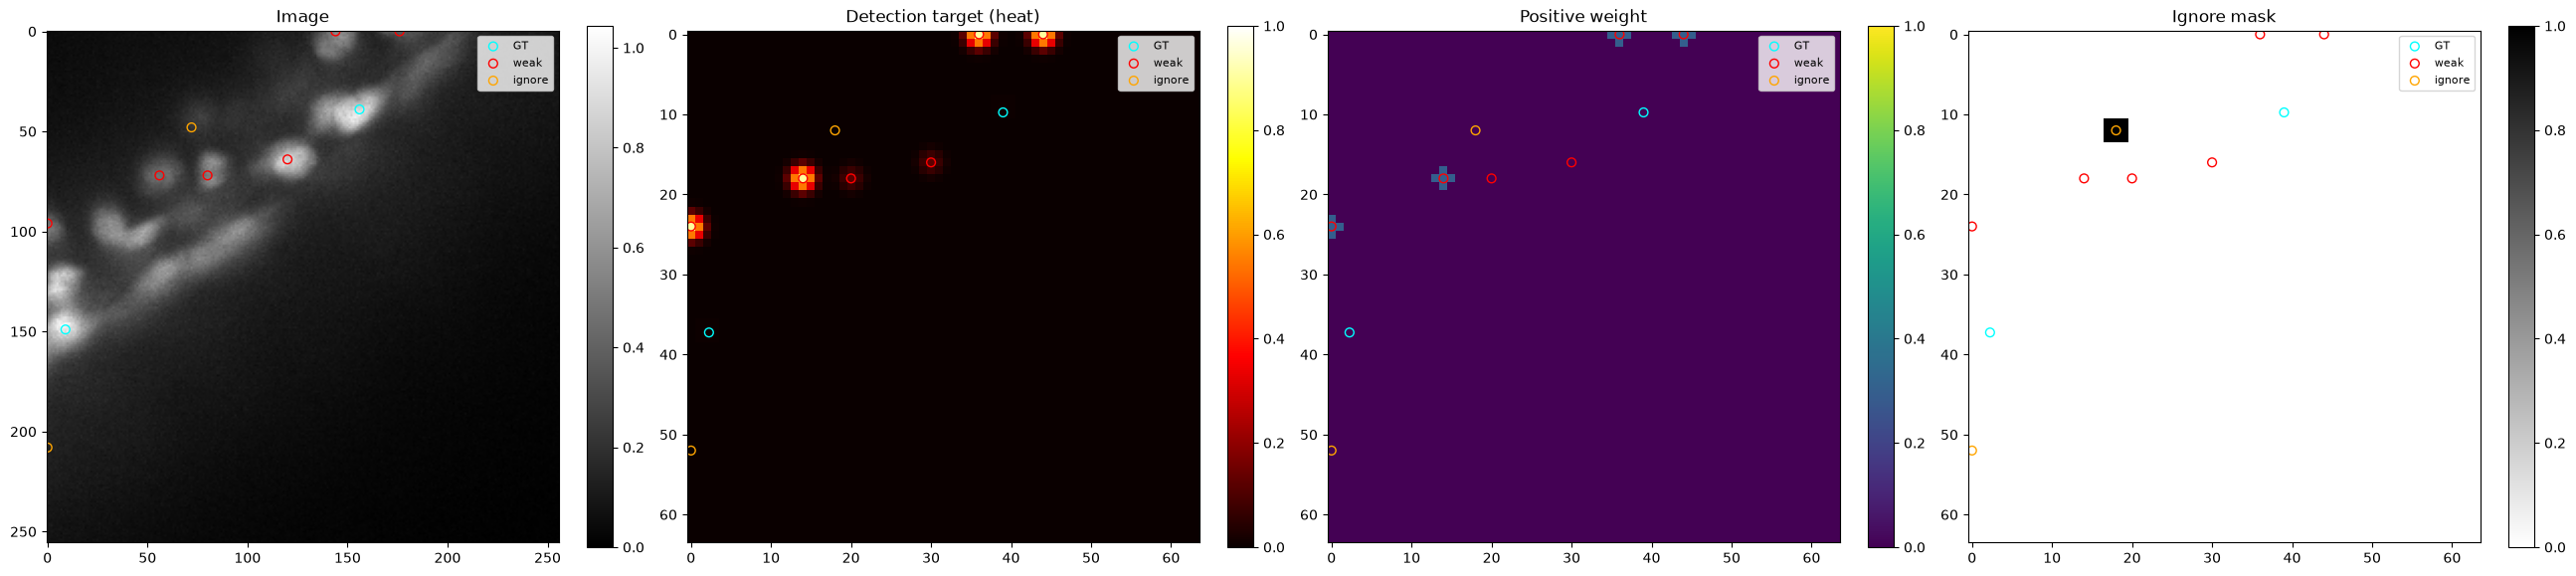

In [87]:
from tracking.losses import build_detection_target

i = 0     # frame index within the window
tol = 3   # only show points within this many z-slices of the plotted slice

gt = coords[0, i][masks[0, i]].cpu().numpy()   # (N, 3) real GT coords, downsampled space
weak = sample["weak_positives"][i].numpy()
weak = weak[(weak >= 0).all(axis=-1)]          # (N, 3), drop -1 padding
ign_pts = sample["ignore_positives"][i].numpy()
ign_pts = ign_pts[(ign_pts >= 0).all(axis=-1)]

# GT is sparse (often a single cell, on a slice with no ignore points), so
# default to the busiest ignore slice — otherwise the ignore panel is empty.
# z = frame  # to match the detection plot above instead
z = int(np.bincount(ign_pts[:, 0].astype(int)).argmax()) if len(ign_pts) else frame

heat, pos_weight, ignore = build_detection_target(
    det_logits[i].shape[2:],
    coords[:, i].clone(),
    masks[:, i],
    unet_scaling=unet_scaling,
    weak_weight=criterion.det_weak_weight,
    weak_smoothing=criterion.det_weak_smoothing,
    gaussian_sigma=criterion.det_gaussian_sigma,
    weak_positives=sample["weak_positives"][i].unsqueeze(0).to(device),
    use_weak_positives=criterion.det_use_weak_positives,
    ignore_positives=sample["ignore_positives"][i].unsqueeze(0).to(device),
    ignore_radius=criterion.det_ignore_radius,
)
z_det = z // unet_scaling[0]

n_pos = int((pos_weight[0, z_det] > 0).sum())
n_ign = 0 if ignore is None else int(ignore[0, z_det].sum())
print(f"z={z} (z_det={z_det})  |  {len(gt)} GT, {len(weak)} weak, {len(ign_pts)} ignore in this frame")
print(f"n_pos = {n_pos}  |  ignored voxels = {n_ign}  |  heat max = {heat.max().item():.2f}")

panels = [
    (sample["imgs"][i].squeeze()[z].cpu().numpy(), "gray", "Image"),
    (heat[0, z_det].cpu().numpy(), "hot", "Detection target (heat)"),
    (pos_weight[0, z_det].cpu().numpy(), "viridis", "Positive weight"),
]
if ignore is not None:
    # Where the negative term is dropped: neither positive nor background.
    panels.append((ignore[0, z_det].float().cpu().numpy(), "gray_r", "Ignore mask"))

fig, axes = plt.subplots(1, len(panels), figsize=(6.5 * len(panels), 6))
for ax, (im, cmap, title) in zip(axes, panels):
    h = ax.imshow(im, cmap=cmap, vmin=0, vmax=1 if title != "Image" else None)
    ax.set_title(title)
    plt.colorbar(h, ax=ax, fraction=0.046)

    # coords are (Z, Y, X); imshow indexes [row=Y, col=X], so scatter as (X, Y).
    scale_z, scale_y, scale_x = (1, 1, 1) if title == "Image" else unet_scaling
    slice_z = z if title == "Image" else z_det

    for pts, color, label in [
        (gt, "cyan", "GT"),
        (weak, "red", "weak"),
        (ign_pts, "orange", "ignore"),
    ]:
        if len(pts) == 0:
            continue
        scaled = pts / np.array([scale_z, scale_y, scale_x], dtype=float)
        scatter_by_depth(
            ax, scaled, slice_z, color, tol=tol, marker="o", s=40,
            linewidths=1, label=label,
        )
    ax.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

In [27]:
# %%time
# loss, breakdown = criterion(
#     det_logits,
#     [coords[:, i] for i in range(window_size)],
#     [masks[:, i] for i in range(window_size)],
#     edge_logits_list,
#     edge_targets_list,
#     det_mask_pairs,
#     imgs_per_frame=[imgs_batch[:, i] for i in range(window_size)],
#     unet_scaling=unet_scaling,
# )

Done !